In [1]:

from pathlib import Path 
import numpy as np  # Numerical operations, including cumulative sums.
import pandas as pd  # Load and summarize tables.
import matplotlib.pyplot as plt  # Create figures and plotting areas.
import seaborn as sns  # Plot directly from table columns.
from IPython.display import display  # Display more than one table in a cell./
from sklearn.preprocessing import StandardScaler  # Put measurements on comparable scales.
from sklearn.decomposition import PCA  # Find linear directions of variation.   
from sklearn.manifold import TSNE  # Create a projection emphasizing neighborhoods.

In [2]:

# load data
try:
    BASE_DIR = Path(__file__).resolve().parent
except NameError:
    # Jupyter Notebook 环境下没有 __file__ 变量
    BASE_DIR = Path.cwd()

DATASETS_DIR = BASE_DIR / "Datasets"

DATASETS_DIR = BASE_DIR / "Datasets"

working_hours = pd.read_csv(
    DATASETS_DIR / "Horas de Trabalho (Our World in Data)/annual-working-hours-per-worker.csv"
)
happiness = pd.read_csv(
    DATASETS_DIR / "World Happiness Report (Kaggle)/happy.csv",
    sep=";",
    decimal=","
)
gdp_per_capita = pd.read_csv(
    DATASETS_DIR / "PIB per Capita (World Bank Open Data)/API_NY.GDP.PCAP.CD_DS2_en_csv_v2_468810.csv",
    # we have to skip the first 4 lintes because they're are about metadata because pandas was trying to parse them as data
    skiprows=4
)

In [3]:
# we make copies so that we don't "ruin" or compromise the original datasets
working_hours_copy = working_hours.copy()
happiness_copy = happiness.copy()
gdp_per_capita_copy = gdp_per_capita.copy()

# print(happiness_copy.columns.tolist())
# print(happiness_copy.head())

# in this "working hours" dataset the year column has a capital Y so we can rename it so they all have the same column's name
working_hours_copy = working_hours_copy.rename(columns={"Year": "year"})
# for the "happy" dataset the date contains the year, so we extract it into a new column
happiness_copy["year"] = pd.to_datetime(
    happiness_copy["Data"],
    format="%d/%m/%Y" # the dates are written in this order
).dt.year # extract only the year

# this is where we have a problem because there isn't a year column, the dataset has columns for every year
gdp_per_capita_copy = gdp_per_capita_copy.melt(
    # so we can keep the columns that identify each country and the indicator and associate them with the values we want
    # the country code is different for every country and works like a primary key as in SQL
    # we also keep the country name, indicator name and indicator code because we don't want to delete any information yet
    id_vars=[
        "Country Name",
        "Country Code",
        "Indicator Name",
        "Indicator Code"
    ],
    # and this indicates which columns have to be converted into lines
    # if the column name contains only digits then it means we found a year column
    value_vars=[
        column for column in gdp_per_capita_copy.columns
        if str(column).isdigit()
    ],
    # with this we tell pandas to grab the columns' names which are the years and transform them into a new column named "year"
    var_name="year",
    # but we can't forget about the values that would be inside those columns, namely the gdp per capita so this grabs those values
    # and puts them in a new column named gdp_per_capita
    value_name="gdp_per_capita"
)

# with this we can go from this:
# Country Name | Country Code | 2021 | 2022 | 2023
# Portugal     | PRT          | ...  | ...  | ...
# to this:
# Country Name | Country Code | year | gdp_per_capita
# Portugal     | PRT          | 2021 | ...

# but we still have to convert them into numerical values for later calculations and operations and things like that
gdp_per_capita_copy["year"] = pd.to_numeric(
    gdp_per_capita_copy["year"],
).astype(int)

In [4]:
combined_datasets = pd.merge(
    happiness_copy,
    working_hours_copy,
    left_on=["Country name", "year"],
    right_on=["Entity", "year"],
    how="inner"
)
combined_datasets = pd.merge(
    combined_datasets,
    gdp_per_capita_copy[["Country Name", "year", "gdp_per_capita"]],
    left_on=["Country name", "year"],
    right_on=["Country Name", "year"],
    how="inner"
)
display(combined_datasets.head())

,Data,Rank,Country name,Ladder score,upperwhisker,lowerwhisker,Explained by: Log GDP per capita,Explained by: Social support,Explained by: Healthy life expectancy,Explained by: Freedom to make life choices,Explained by: Generosity,Explained by: Perceptions of corruption,Dystopia + residual,year,Entity,Code,Working hours per worker,World region according to OWID,Country Name,gdp_per_capita
0,01/01/2023,87,Albania,5.3040,5.440000,5.168000,1.438000,0.924000,0.63800,0.690000,0.138000,0.049000,1.428000,2023,Albania,ALB,2151.97,Europe,Albania,9740.702341
1,01/01/2022,83,Albania,5.2770,5.406000,5.148000,1.449000,0.951000,0.48000,0.549000,0.133000,0.037000,1.678000,2022,Albania,ALB,2160.98,Europe,Albania,7756.961887
2,01/01/2021,90,Albania,5.1990,5.321000,5.076000,1.439000,0.646000,0.71900,0.511000,0.138000,0.028000,1.718000,2021,Albania,ALB,2125.82,Europe,Albania,7242.455131
3,01/01/2020,94,Albania,5.1170,5.234000,5.001000,1.008000,0.529000,0.64600,0.491000,0.168000,0.024000,2.250000,2020,Albania,ALB,2042.15,Europe,Albania,6027.913507
4,01/01/2019,105,Albania,4.8827,4.992687,4.772713,0.906653,0.830484,0.84633,0.461946,0.171028,0.025361,1.640897,2019,Albania,ALB,2142.84,Europe,Albania,6069.439031


In [5]:
# Q2 visualization: Working Hour vs Happiness, ou associate with GDP
df_Q3 = combined_datasets[
    [
        "Country name",
        "year",
        "Working hours per worker",
        "Ladder score",
        "gdp_per_capita"
     ]
].copy()

# Remove missing values
df_Q3 = df_Q3.dropna()

# Remove invalid values

valid_data_Q3 = df_Q3[
    (df_Q3["Working hours per worker"] > 0) &
    (df_Q3["Ladder score"] > 0) &
    (df_Q3["gdp_per_capita"] > 0)
]

# display(df_Q3.head())
# Check how many countries have data available for analysis each year.

# print(valid_data_Q3.groupby("year")["Country name"].nunique())






In [6]:

# calculate median GDP per capita foe each country
country_gdp = valid_data_Q3.groupby("Country name")[
    "gdp_per_capita"
].median().reset_index()

# Divide counties into three GDP groups
country_gdp["GDP_group"] = pd.qcut(
    country_gdp["gdp_per_capita"],
    q = 3,
    labels=["low GDP","Middle GDP", "High GDP"]
)
# Merge GDP groups into dataset
valid_data_Q3  = pd.merge(
    valid_data_Q3,
    country_gdp[["Country name","GDP_group"]],
    on=["Country name"],
    how="inner"
)
display(valid_data_Q3.head())

,Country name,year,Working hours per worker,Ladder score,gdp_per_capita,GDP_group
0,Albania,2023,2151.97,5.3040,9740.702341,Middle GDP
1,Albania,2022,2160.98,5.2770,7756.961887,Middle GDP
2,Albania,2021,2125.82,5.1990,7242.455131,Middle GDP
3,Albania,2020,2042.15,5.1170,6027.913507,Middle GDP
4,Albania,2019,2142.84,4.8827,6069.439031,Middle GDP


In [7]:
# correlation for all observations
r_all = valid_data_Q3["Working hours per worker"].corr(
    valid_data_Q3["Ladder score"]
)


# correlation for each group 计算相关关系，-1~1，
correlation_of_each_group = valid_data_Q3.groupby(
    "GDP_group",observed=True
).apply(
    lambda group: group["Working hours per worker"].corr(group["Ladder score"])
)
print(f"All countries: {r_all:.3f}")
print(correlation_of_each_group)

All countries: -0.406
GDP_group
low GDP       0.212340
Middle GDP   -0.212155
High GDP     -0.381762
dtype: float64


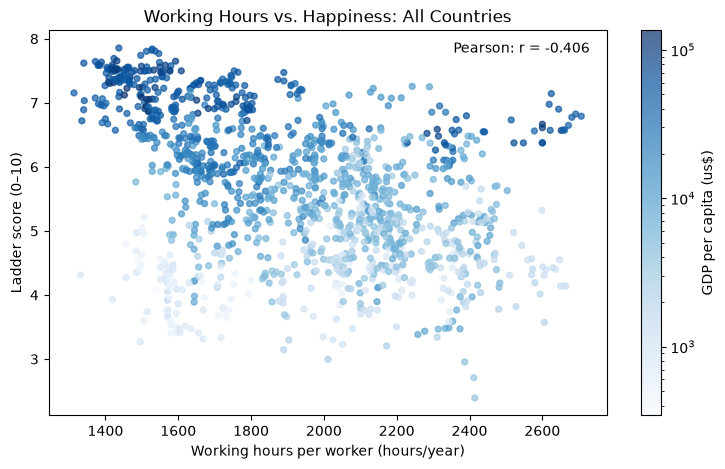

In [8]:
from matplotlib.colors import LogNorm
# map 4 scatterplots , one for all data, three for each group
gdp_min = valid_data_Q3["gdp_per_capita"].min()
gdp_max = valid_data_Q3["gdp_per_capita"].max()


fig, ax = plt.subplots(figsize=(9, 5))
marks = ax.scatter(
    data=valid_data_Q3,
    x="Working hours per worker",
    y="Ladder score",
    c=valid_data_Q3["gdp_per_capita"],
    cmap="Blues",
    # vmin=gdp_min,
    # vmax=gdp_max,
    norm=LogNorm(
        vmin=valid_data_Q3["gdp_per_capita"].min(),
        vmax=valid_data_Q3["gdp_per_capita"].max()
    ),
    s=18,
    alpha=0.7,
)

fig.colorbar(marks, ax=ax, label="GDP per capita (us$)")

ax.set_title("Working Hours vs. Happiness: All Countries")
ax.set_xlabel("Working hours per worker (hours/year)")
ax.set_ylabel("Ladder score (0–10)")
ax.text(
    0.97,0.97,
    f"Pearson: r = {r_all:.3f}",
    transform=ax.transAxes,
    ha="right",
    va="top"
    )
plt.show()


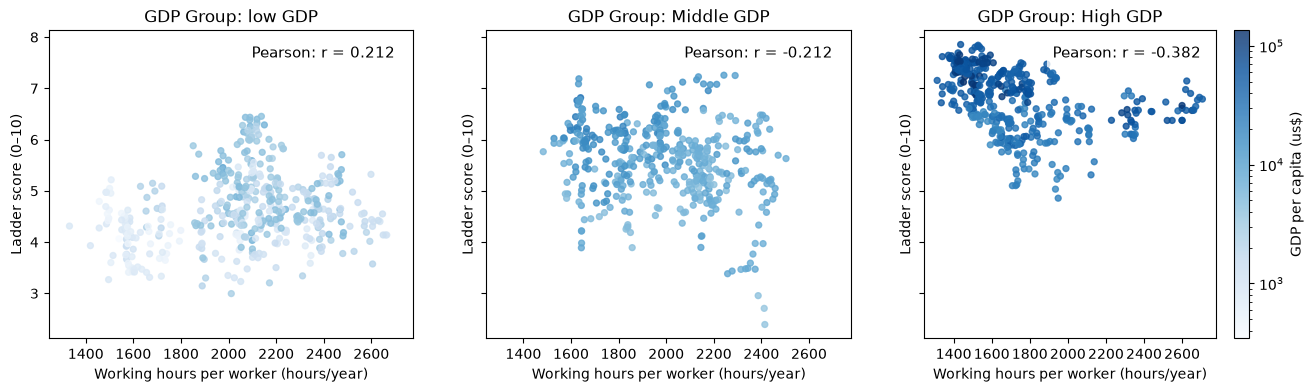

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4), sharex=True, sharey=True)

group_order = ["low GDP","Middle GDP", "High GDP"]
for ax, group_name in zip(axes, group_order):

    group_data = valid_data_Q3[valid_data_Q3["GDP_group"] == group_name]
    marks = ax.scatter(
    data=group_data,
    x="Working hours per worker",
    y="Ladder score",
    c=group_data["gdp_per_capita"],
    cmap="Blues",
    # vmin=gdp_min,
    # vmax=gdp_max,
    norm=LogNorm(
        vmin=valid_data_Q3["gdp_per_capita"].min(),
        vmax=valid_data_Q3["gdp_per_capita"].max()
    ),
    s=18,
    alpha=0.8,
    )
    r = correlation_of_each_group[group_name]
    ax.set_title(f"GDP Group: {group_name}")
    ax.set_xlabel("Working hours per worker (hours/year)")
    ax.set_ylabel("Ladder score (0–10)")

    ax.text(
        0.95, 0.95,
        f"Pearson: r = {r:.3f}",
        transform=ax.transAxes,
        fontsize=11,
        va="top",
        ha="right",
        bbox=dict(facecolor="white", alpha=0.8, edgecolor="none")
    )
fig.colorbar(marks, ax=ax, label="GDP per capita (us$)")


plt.show()